# Итоговый проект по модулю "Математика и статистика"

В качестве набора данных будем использовать базу данных Simulative с информацией по решению задач и тестов студентами курса

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import *
import psycopg2
from sqlalchemy import create_engine
from configparser import ConfigParser

## Гипотеза №1

### Описание задачи

Мы хотим узнать какой курс популярнее (SQL или Python), чтобы усилить на него рекламу. Для этого сравним среднее количество попыток решения задач в разбивке по языку программирования.

`H0:` Среднее количество попыток решения по двум курсам не отличается. 

`H1:` Среднее количество попыток решения по двум курсам отличается

`alpha` = 0.05

In [2]:
config = ConfigParser()
config.read('config.ini', encoding="utf-8")

host=config['Database']['HOST']
port=config['Database']['PORT']
database=config['Database']['DATABASE']
user=config['Database']['USER']
password=config['Database']['PASSWORD']

connection = create_engine(f'postgresql+psycopg2://{user}:{password}@{host}/{database}')

Загружаем данные

In [3]:
sql_query = """
    with problem_tries as (select problem_id, language_id, user_id
        from codesubmit c
        union all
        select problem_id, language_id, user_id
        from coderun c2
)
select 
	name,
	user_id,
	count(problem_id)
from problem_tries c
join languagetoproblem l
on c.problem_id = l.pr_id and c.language_id = l.lang_id
join "language" l2
on l.lang_id = l2.id
where l2."name" = 'SQL'
or l2."name" = 'Python'
group by 1,2
"""

data = pd.read_sql(sql_query, connection)
data

,name,user_id,count
0,Python,1,4
1,Python,2,991
2,Python,3,3
3,Python,4,3
4,Python,5,2
...,...,...,...
1115,SQL,2785,87
1116,SQL,2786,196
1117,SQL,2796,154
1118,SQL,2803,4


Визуализируем распределения количества попыток пользователей по группам языков

<Axes: title={'center': 'count'}, xlabel='name'>

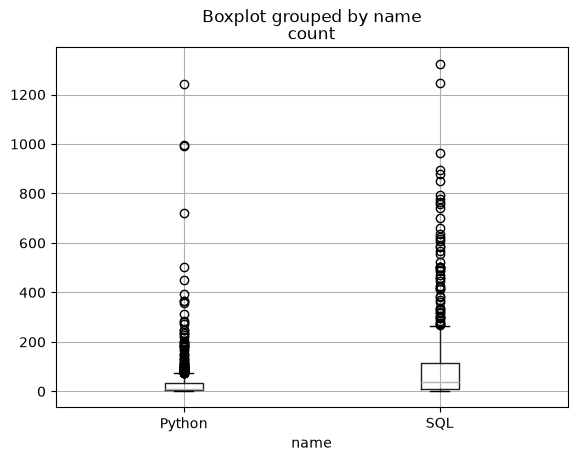

In [4]:
data.boxplot(by='name', column='count')

array([<Axes: title={'center': 'Python'}>,
       <Axes: title={'center': 'SQL'}>], dtype=object)

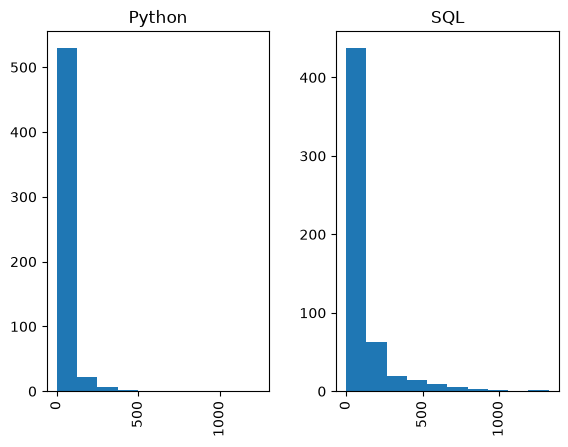

In [5]:
data.hist(by='name', column='count')

Для проверки гипотезы будем использовать критерий Краскела-Уоллиса, так как данные распределены ненормально

In [6]:
from scipy.stats import kruskal

python_cnt = data[data['name']=='Python']['count']
sql_cnt = data[data['name']=='SQL']['count']

kruskal(python_cnt, sql_cnt)

KruskalResult(statistic=np.float64(105.29943384206668), pvalue=np.float64(1.050061544934325e-24))

<b>Вывод:</b> Так как p-value < 0.05, то мы можем отвергнуть нулевую гипотезу о равенстве среднего значения количества попыток решения по курсам

## Гипотеза №2

### Описание задачи

Мы хотим узнать есть ли связь между сложностью вопросов в тестах и правильными ответами.

`H0:` Связь между сложностью вопросов в тестах и правильными ответами есть 

`H1:` Связи между сложностью вопросов в тестах и правильными ответами нет 

Загружаем данные

In [7]:
sql_query = """
select 
	case when complexity = 1 then 0 else 1 end as complexity, case when t4.is_correct is true then 1 else 0 end as is_correct
from users u
join testresult t 
on u.id = t.user_id 
join test t2 
on t.test_id = t2.id
join testquestion t3 
on t2.id = t3.test_id and t.question_id = t3.id
left join testanswer t4 
on t3.id = t4.question_id and t.answer_id = t4.id 
where u.company_id is not null and t4.is_correct is not null
"""

data = pd.read_sql(sql_query, connection)
data.head()

,complexity,is_correct
0,1,0
1,1,0
2,1,0
3,1,1
4,1,0


Для проверки связи между двуми бинарными переменными будем использовать коэффициент φ (Фи)

In [8]:
q1 = data['complexity']
q2 = data['is_correct']

a = sum(q1*q2)
b = sum(q1>q2)
c = sum(q1<q2)
d = len(q1) - a - b -c
phi = (a * d - b * c) / np.sqrt((a + b) * (c + d) * (a + c) * (b + d))

In [9]:
phi

np.float64(-0.06103993311543538)

<b>Вывод:</b> Так как коэффициент φ равен -0.06, то мы можем сказать что между сложностью вопросов и правильными ответами нет связи

## Гипотеза №3

### Описание задачи

Мы хотим понять есть ли зависимость между количеством попыток решения задач и днями недели. Это поможет выявить дни когда эффективность учеников снижается и предложить им мотивационный бонус чтобы они не забрасывали обучение и дольше оставались на платформе

`H0`: Зависимости между количеством попыток решения задач и днями недели нет

`H1`: Зависимость между количеством попыток решения задач и днями недели есть

Загружаем данные

In [10]:
sql_query = """
with problem_tries as (select extract(isodow from created_at) AS day_of_week, problem_id
from codesubmit c
union all
select extract(isodow from created_at) AS day_of_week, problem_id
from coderun c2)
select day_of_week,problem_id, count(*)
from problem_tries pt
left join problem p
on pt.problem_id = p.id
group by 1,2
"""

data = pd.read_sql(sql_query, connection)
data.head()

,day_of_week,problem_id,count
0,7.0,50,37
1,3.0,242,1
2,1.0,125,96
3,3.0,212,1
4,4.0,116,66


Визуализируем данные

<Axes: xlabel='day_of_week', ylabel='count'>

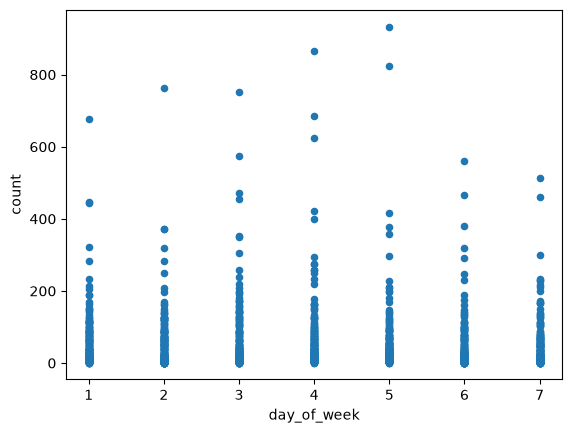

In [11]:
data.plot.scatter(x='day_of_week', y ='count')

(array([154.,  30.,  13.,   5.,   5.,   1.,   0.,   0.,   1.,   1.]),
 array([  1. ,  52.1, 103.2, 154.3, 205.4, 256.5, 307.6, 358.7, 409.8,
        460.9, 512. ]),
 <BarContainer object of 10 artists>)

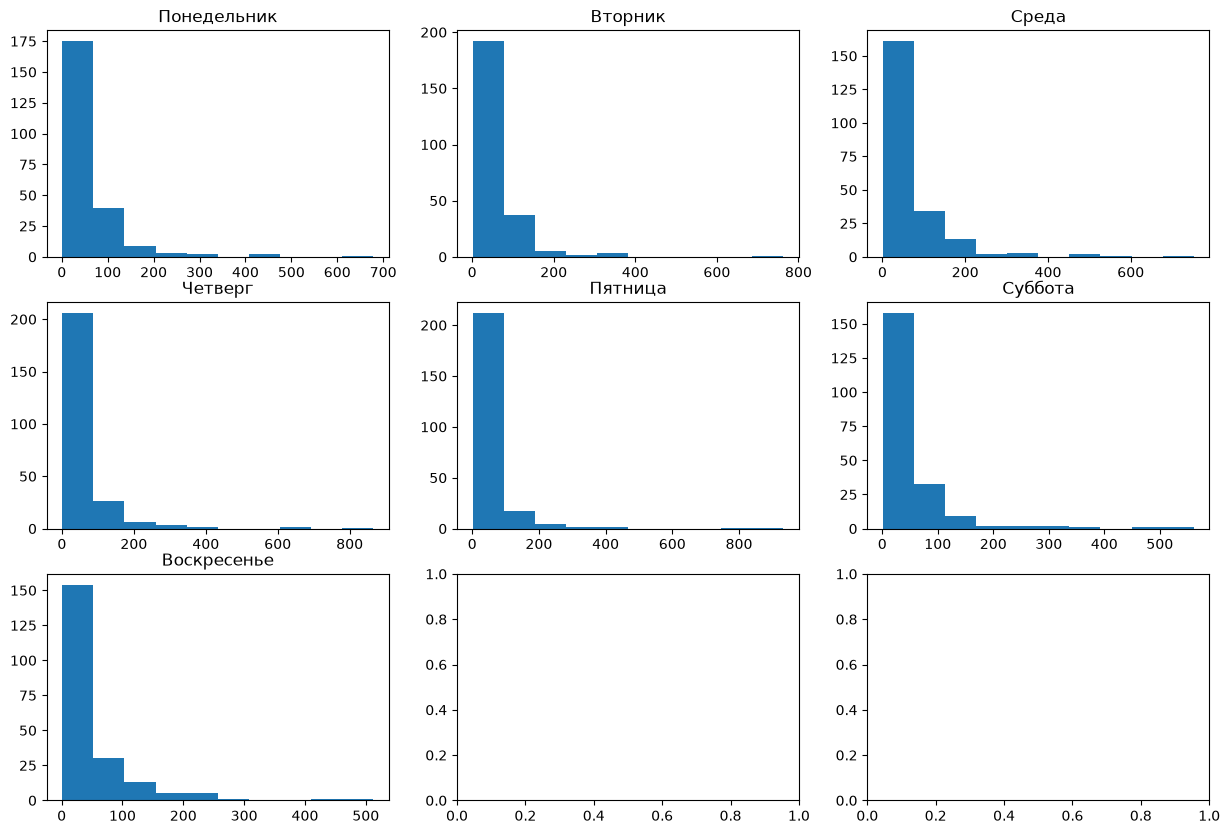

In [12]:
from matplotlib import pyplot as plt


fig, ax = plt.subplots(3,3, figsize=(15,10))

ax[0,0].set_title('Понедельник')
ax[0,0].hist(data['count'][data['day_of_week']==1])

ax[0,1].set_title('Вторник')
ax[0,1].hist(data['count'][data['day_of_week']==2])

ax[0,2].set_title('Среда')
ax[0,2].hist(data['count'][data['day_of_week']==3])

ax[1,0].set_title('Четверг')
ax[1,0].hist(data['count'][data['day_of_week']==4])

ax[1,1].set_title('Пятница')
ax[1,1].hist(data['count'][data['day_of_week']==5])

ax[1,2].set_title('Суббота')
ax[1,2].hist(data['count'][data['day_of_week']==6])

ax[2,0].set_title('Воскресенье')
ax[2,0].hist(data['count'][data['day_of_week']==7])

#data.hist(by='day_of_week', column='count')

Распределение количества попыток решения задач по дням недели достаточно похоже. Явной зависимости не наблюдается.

Для проверки гипотезы будем использовать корреляцию Спирмена, так как данные распределены ненормально и есть порядковая переменная (день недели)

Расчитаем корреляцию Спирмена

In [13]:
from scipy.stats import spearmanr

spearmanr(data['day_of_week'], data['count'])

SignificanceResult(statistic=np.float64(-0.04175194285314496), pvalue=np.float64(0.095641270484325))

<b>Вывод:</b> Так как p-value > 0.05, значит мы не можем отвергнуть нулевую гипотезу о том, что нет зависимости между количеством попыток решения задач и днями недели

## Гипотеза №4

### Описание задачи

Мы хотим понять отличается ли транзакционная активности пользователей между теми кто зарегистрировался на платформе в Q1 и теми зарегистрировался на платформе в Q2. 

`H0`: Средняя сумма покупок задач не отличается

`H1`: Средняя сумма покупок задач отличается

Загружаем данные

In [14]:
sql_query = """
select 
	u.date_joined::date,
	case when u.date_joined <= '2022-02-28' then 'Q1' else 'Q2' end as quarter,
	u.id as user_id,
	sum(coalesce(t.value,0)) as transaction_sum
from users u
left join "transaction" t 
on u.id = t.user_id
where u.date_joined::date >= '2022-01-01' and u.date_joined::date <= '2022-04-21'
and type_id in (23,27)
group by 1,2,3
"""

data = pd.read_sql(sql_query, connection)
data.head()

,date_joined,quarter,user_id,transaction_sum
0,2022-01-01,Q1,414,0
1,2022-01-02,Q1,416,0
2,2022-01-02,Q1,417,30
3,2022-01-03,Q1,418,0
4,2022-01-03,Q1,420,30


Визуализируем данные

array([<Axes: title={'center': 'Q1'}>, <Axes: title={'center': 'Q2'}>],
      dtype=object)

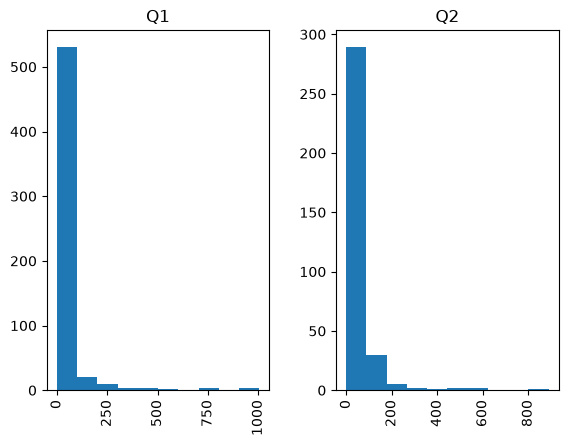

In [15]:
data.hist(by='quarter', column='transaction_sum')

Так как данные распределены ненормально, то мы не можем использовать параметрические критерии для проверки гипотезы. Поэтому будем использовать критерий Краскела-Уоллиса

In [16]:
from scipy.stats import kruskal

q1 = data[data['quarter'] == 'Q1']['transaction_sum']
q2 = data[data['quarter'] == 'Q2']['transaction_sum']

kruskal(q1, q2)

KruskalResult(statistic=np.float64(0.9798972171579939), pvalue=np.float64(0.3222241829067339))

<b>Вывод:</b> Так как p-value > 0.05, значит мы не можем отвергнуть нулевую гипотезу о том, что средняя сумма покупок задач и тестов по кварталам не отличается

## Гипотеза №5

### Описание задачи

В качестве эксперимента мы в январе 2022 года предложили новым пользователям 500 рублей на телефон если они решат 5 задач среднего уровня. Мы хотим понять отличается ли Retention 1 дня у когорты пользователей которым предложили бонус от когорты которой не предложили (февраль 2022 года).

`H0`: Retention 1 Day не отличается между когортами

`H1`: Retention 1 Day у когорты января больше чем у когорты февраля (правостороння гипотеза)

Загружаем данные

In [17]:
sql_query = """
with absolute_count as (select 
	to_char(date_joined, 'YYYY-MM') as cohort,
	count(case when diff = 0 then 1 end) as day_0,
	count(case when diff = 1 then 1 end) as day_1,
	count(case when diff = 3 then 1 end) as day_3,
	count(case when diff = 7 then 1 end) as day_7,
	count(case when diff = 14 then 1 end)as day_14,
	count(case when diff = 30 then 1 end)as day_30,
	count(case when diff = 60 then 1 end)as day_60,
	count(case when diff = 90 then 1 end)as day_90
from (
select distinct u.id, u.date_joined, extract(day from u2.entry_at - u.date_joined)::numeric as diff
from users u 
left join userentry u2 
on u.id = u2.user_id
where date_joined::date >= '2022-01-01' and date_joined::date <= '2022-02-28' and u2.entry_at is not null
) diff_day
group by cohort
)
select 
	cohort,
	day_0,
	day_1,
    round(day_1 / day_0::numeric,2) as "retention_1_dat"
from absolute_count
"""

data = pd.read_sql(sql_query, connection)
data.head()

,cohort,day_0,day_1,retention_1_dat
0,2022-01,481,84,0.17
1,2022-02,883,94,0.11


In [18]:
# Выборочные доли признака
p1 = 0.17
p2 = 0.11

# Объемы выборок
n1 = 481
n2 = 883

# Число объектов в выборке, обладающих признаком
m1 = 84
m2 = 94

# Общая доля элементов с признаком в двух выборках
p = (m1+m2)/(n1+n2)

# Посчитаем статистику Z-критерия
z = (p1-p2)/np.sqrt(p*(1-p)/n1+p*(1-p)/n2)
z

np.float64(3.1431056538974693)

Найдем p-value для правосторонней гипотезы от полученного значения Z-критерия

In [19]:
from scipy.stats import norm
norm.sf(z)

np.float64(0.0008358274512150608)

<b>Вывод:</b> Так как p-value < 0.05, значит мы можем отвергнуть нулевую гипотезу о том, что средняя сумма покупок задач и тестов по кварталам не отличается

## Гипотеза №6

### Описание задачи

Мы предположили, что в первом полугодии 2022 года количество транзакций (зачислений и списаний) у корпоративных пользователей будет распределяться следующим образом:

1. Компания 2 - 12%, 
2. Компания 4 - 20%, 
3. Компания 6 - 10%, 
4. Компания 7 - 38%, 
5. Компания 8 - 9%, 
6. Компания 10 - 11%

`H0`: Теоритические доли значимо не отличаются от фактических

`H1`: Теоритические доли значимо отличаются от фактических

Загружаем данные

In [20]:
sql_query = """
with writeoff as (select user_id, count(value) as write_off
from "transaction" t 
where (type_id = 1 or type_id >= 23 and type_id <= 28 and type_id != 30) and value < 500
and created_at::date >= '2022-01-01' and created_at::date <= '2022-05-24'
group by user_id),
accrual as (select user_id, count(value) as accruals
from "transaction" t 
where (type_id = 29 or type_id >= 2 and type_id <= 22 and type_id != 30) and value < 500
and created_at::date >= '2022-01-01' and created_at::date <= '2022-05-24'
group by user_id),
agg as (select u.id, u.company_id, write_off, accruals
from users u 
left join writeoff
on u.id = writeoff.user_id
left join accrual
on u.id = accrual.user_id
where coalesce (u.company_id,0) != 1
)
select company_id, 
count(coalesce(write_off, accruals))
from agg
where company_id is not null
group by company_id
"""

data = pd.read_sql(sql_query, connection)
data.head()

,company_id,count
0,2,1
1,4,47
2,6,9
3,7,37
4,8,1


У нас есть фактические абсолютные частоты. Рассчитаем теоретические абсолютные частоты: умножим общее количество товаров на количество процентов:

In [21]:
N = sum(data['count'])
teoretic_freq = [0.12*N, 0.2*N, 0.1*N, 0.38*N, 0.09*N, 0.11*N]
teoretic_freq

[12.84,
 21.400000000000002,
 10.700000000000001,
 40.660000000000004,
 9.629999999999999,
 11.77]

Составим таблицу сопряженности

In [22]:
table = np.array([data['count'],teoretic_freq])
table

array([[ 1.  , 47.  ,  9.  , 37.  ,  1.  , 12.  ],
       [12.84, 21.4 , 10.7 , 40.66,  9.63, 11.77]])

Рассчитаем критерий хи-квадрат Пирсона

In [23]:
from scipy.stats import chi2_contingency

chi2_contingency(table)

Chi2ContingencyResult(statistic=np.float64(27.038013744138492), pvalue=np.float64(5.607832612491403e-05), dof=5, expected_freq=array([[ 6.92 , 34.2  ,  9.85 , 38.83 ,  5.315, 11.885],
       [ 6.92 , 34.2  ,  9.85 , 38.83 ,  5.315, 11.885]]))

<b>Вывод:</b> Так p-value < 0.05, то мы можем отклонить нулевую гипотезу о том, что фактические и теоретические частоты значимо не отличаются. То есть реальное количество транзакций значимо отличаются от ожидаемых.